# Interaction nets in three rules

An *interaction net* is a graph of **agents**. Each agent has one **principal port**, through which it interacts, and some auxiliary ports. Where a wire joins two principal ports there is an **active pair**, and a rule replaces the pair by a small net. That is all a net can do.

This notebook uses the smallest interesting system, the *symmetric interaction combinators*: a constructor `con`, a duplicator `dup` and an eraser `era`. The kernel starts with their table loaded.

In [1]:
%table

# The symmetric interaction combinators: two binary agents and an eraser.
#
# Lafont showed (1997) that three agents of this kind suffice for any interaction system;
# these are the symmetric ones, in which both binary agents annihilate straight across.
# The IVM's `ivm:x` and `ivm:y` behave as `con` and `dup` do here.

agent con 2      # a constructor
agent dup 2      # a duplicator
agent era 0      # an eraser

# Two of a kind annihilate: their ports are joined straight across.
rule con (a b) >< con (c d)
  => a = c; b = d
  count annihilate

rule dup (a b) >< dup (c d)
  => a = c; b = d
  count annihilate

# Two of different kinds pass through each other, each copying the other.
rule con (a b) >< dup (c d)
  => a = dup (p q); b = dup (r s); c = con (p r); d = con (q s)
  count commute

# An eraser erases, and sends erasers on.
rule era >< con (a b)
  => a = era; b = era
  count erase

rule era >< dup (a b)
  => a = era; b = era
  count erase

rule era >< era
  => nothing
  count era

A cell that is not a table or a command is a **net**, written as the right-hand side of a rule is. `con (a b)` is a node and stands for its principal port. A name used twice is a wire; a name used once is a free port, a loose end.

In the pictures, drawn as in Lafont's figures, an arrowhead marks each principal port, so an active pair shows as two arrowheads tip to tip (`%style ports` draws boxes with port numbers instead, port 0 being the principal port).

## Two of a kind annihilate

the net:


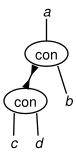

stopped: no active pair is left (normal); 1 interaction; 0 active pairs left; annihilate 1


what is left:


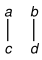

In [2]:
con (a b) = con (c d)

The two nodes are gone, and `a` is joined to `c` and `b` to `d`.

## Two of different kinds copy each other

the net:


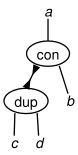

stopped: no active pair is left (normal); 1 interaction; 0 active pairs left; commute 1


what is left:


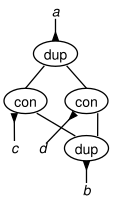

In [3]:
con (a b) = dup (c d)

One interaction, and each node has been copied by the other. This is how a net duplicates: one node at a time.

## An eraser erases, and sends erasers on

the net:


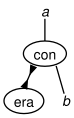

stopped: no active pair is left (normal); 1 interaction; 0 active pairs left; erase 1


what is left:


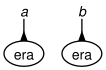

In [4]:
era = con (a b)

## Putting them together

A duplicator copying a small tree of constructors whose leaves are erasers. Watch it round by round: every active pair in a round fires at once, as a parallel machine would do it.

schedule: rounds


trace: on


the net:


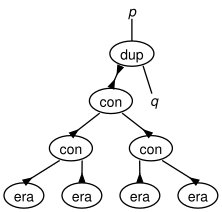

after round 1:


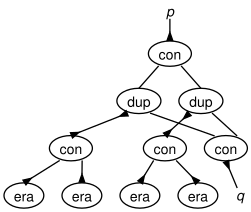

after round 2:


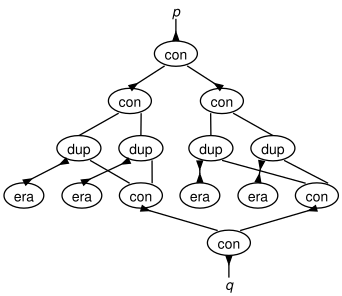

after round 3:


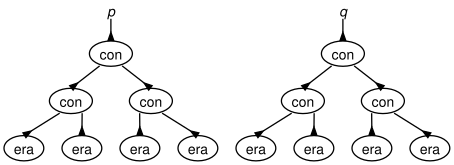

stopped: no active pair is left (normal); 7 interactions, in 3 rounds, the widest of 4; 0 active pairs left; commute 3, erase 4


In [5]:
%schedule rounds
%trace on
con (con (era era) con (era era)) = dup (p q)

The duplicator went through the tree one node at a time, leaving `p` and `q` each with a copy.

The number of rounds is the net's **span**: the longest chain of interactions that must follow one another. For a net that reaches a normal form, the order in which pairs fire does not change the result or the number of interactions. That is a theorem about interaction nets (strong confluence); here it is on this net, with one pair fired at a time in two different orders.

trace: off


schedule: stack


the net:


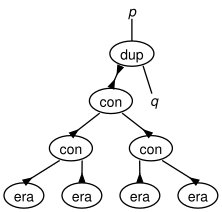

stopped: no active pair is left (normal); 7 interactions; 0 active pairs left; commute 3, erase 4


what is left:


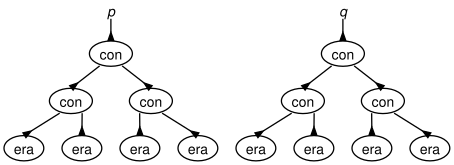

In [6]:
%trace off
%schedule stack
con (con (era era) con (era era)) = dup (p q)

schedule: queue


the net:


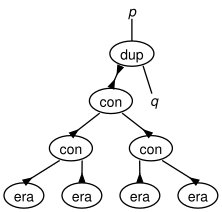

stopped: no active pair is left (normal); 7 interactions; 0 active pairs left; commute 3, erase 4


what is left:


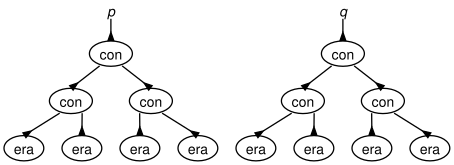

In [7]:
%schedule queue
con (con (era era) con (era era)) = dup (p q)